# ME256 Homework 4: variations, thin plates, and a hanging chain

**Official statement:** [ME256 Homework 4 (2011)](https://mecheng.iisc.ac.in/suresh/me256/hw2011/homework4.html), assigned February 8 and due February 15, 2011.

This notebook develops the three requested problems: a Gateaux variation, the field equation and boundary conditions for a thin plate, and analytical/numerical solutions for a suspended chain. NumPy, SciPy, and Matplotlib are used for the numerical example.

## 1. Gateaux variation of a quotient

For

$$R[w]=\frac{N[w]}{M[w]}=
\frac{\int_0^L EI\,(w'')^2\,dx}{\int_0^L \rho w^2\,dx},$$

take an admissible perturbation $w_\epsilon=w+\epsilon\eta$. With $EI$ and $\rho$ fixed,

$$N'[w;\eta]=2\int_0^L EI\,w''\eta''\,dx,\qquad
M'[w;\eta]=2\int_0^L \rho w\eta\,dx,$$

and therefore

$$\delta R[w;\eta]=
\left.\frac{d}{d\epsilon}R[w+\epsilon\eta]\right|_{\epsilon=0}
=\frac{2}{M[w]}\left[
\int_0^L EI\,w''\eta''\,dx
-R[w]\int_0^L \rho w\eta\,dx\right].$$

Integrating the first integral by parts twice gives the interior expression
$(EIw'')''-R\rho w$ and boundary terms
$[EIw''\eta'-(EIw'')'\eta]_0^L$. Thus the stationary quotient satisfies the generalized eigen-equation
$(EIw'')''=R\rho w$, together with boundary conditions determined by the admissible end variations.

## 2. Thin plate: field equation and edge conditions

Let $w(x,y)$ be the transverse deflection and $\nu$ Poisson's ratio. The bending density in the assignment is equivalently

$$\frac D2\left[w_{xx}^2+w_{yy}^2+2\nu w_{xx}w_{yy}
+2(1-\nu)w_{xy}^2\right]-qw.$$

Its first variation gives the equilibrium equation

$$D\nabla^4w=q,$$

where $\nabla^4w=w_{xxxx}+2w_{xxyy}+w_{yyyy}$.

Define moment resultants
$$M_x=D(w_{xx}+\nu w_{yy}),\quad
M_y=D(w_{yy}+\nu w_{xx}),\quad
M_{xy}=D(1-\nu)w_{xy}.$$
For boundary unit normal $n$ and tangent $s$, let $M_{nn}=n^TMn$,
$M_{ns}=n^TMs$, and
$$V_n=n\cdot(\nabla\cdot M)+\frac{\partial M_{ns}}{\partial s},$$
with $M=\begin{bmatrix}M_x&M_{xy}\\M_{xy}&M_y\end{bmatrix}$.
The boundary virtual work pairs $M_{nn}$ with the normal slope and $V_n$ with transverse displacement. Consequently:

- **Clamped edge:** prescribe $w$ and $\partial w/\partial n$ (commonly both zero).
- **Simply supported edge:** prescribe $w$ and the normal bending moment $M_{nn}$ (commonly both zero).
- **Free edge:** prescribe $M_{nn}$ and the effective shear $V_n$ (commonly both zero).
- **Mixed/load-controlled edge:** at each location prescribe either a kinematic quantity or its conjugate moment/shear. At corners, twisting-moment jumps must balance any applied corner force or couple.

These are alternative edge-condition types, selected according to the support and loading; they are not all imposed simultaneously on the same boundary segment.

The assignment displays a particular expression relating $D$ to $E,t,\nu$. The variational equation above uses $D$ symbolically; check the constitutive convention and units before using that displayed relation in a physical design calculation.

## 3. Hanging chain: variational model and catenary

Let $y(x)$ describe the chain from $(0,a_0)$ to $(b,c_0)$. Its length and gravitational potential energy are

$$\mathcal L[y]=\int_0^b\sqrt{1+y'^2}\,dx=L,\qquad
\Pi[y]=mg\int_0^b y\sqrt{1+y'^2}\,dx.$$

The endpoints are fixed. Introducing the length multiplier $\Lambda$ (units of force), the augmented integrand is
$F=(mg y+\Lambda)\sqrt{1+y'^2}$. Since $F$ has no explicit $x$ dependence, the first integral is

$$F-y'F_{y'}=\frac{mg y+\Lambda}{\sqrt{1+y'^2}}=mg\alpha,$$

where $\alpha>0$ is a length. This yields

$$y(x)=\alpha\cosh\left(\frac{x-x_0}{\alpha}\right)+C,
\qquad \Lambda=-mgC.$$

The catenary parameter is determined by the endpoint height difference and prescribed arc length. The multiplier is datum-dependent in isolation: the physical tension magnitude is $T(x)=mg(y+\Lambda/(mg))$, and its constant horizontal component is $H=mg\alpha$. This provides the mechanical interpretation of the multiplier through the tension field.

The numerical example uses supports $(0,2)$ and $(5,7)$, a chain length of $12$ m, and 15 segments. The discrete solution is compared with the analytical catenary.

### Analytical catenary for the example data

Using endpoint difference $\Delta y=5$ m, eliminate the vertical shift and express the center as a function of $\alpha$:

$$x_0=\frac b2-\alpha\,\operatorname{asinh}\left(
\frac{\Delta y}{2\alpha\sinh(b/(2\alpha))}\right).$$

The arc-length equation is

$$L=2\alpha\sinh\left(\frac b{2\alpha}\right)
\cosh\left(\frac{b/2-x_0}{\alpha}\right).$$

After solving for $\alpha$, the endpoint fixes $C=a_0-\alpha\cosh(x_0/\alpha)$ and the length multiplier follows from $\Lambda=-mgC$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq, minimize


In [2]:
# Example data: the two supports are (0, 2 m) and (5 m, 7 m).
horizontal_span = 5.0
left_height = 2.0
right_height = 7.0
chain_length = 12.0
linear_density = 1.2  # kg/m
gravity = 9.81  # m/s^2
height_difference = right_height - left_height


def catenary_parameters(scale):
    half_span_ratio = horizontal_span / (2.0 * scale)
    center_offset = scale * np.arcsinh(
        height_difference
        / (2.0 * scale * np.sinh(half_span_ratio))
    )
    center_x = horizontal_span / 2.0 - center_offset
    predicted_length = (
        2.0
        * scale
        * np.sinh(half_span_ratio)
        * np.cosh(center_offset / scale)
    )
    return predicted_length, center_x


def length_residual(scale):
    return catenary_parameters(scale)[0] - chain_length


# The bracket avoids the large-scale hyperbolic overflow of an unbounded root search.
catenary_scale = brentq(length_residual, 0.05, 100.0, xtol=1e-13)
analytic_length, catenary_center_x = catenary_parameters(catenary_scale)
vertical_shift = left_height - catenary_scale * np.cosh(
    catenary_center_x / catenary_scale
)
normalized_multiplier = -vertical_shift
physical_multiplier = linear_density * gravity * normalized_multiplier
horizontal_tension = linear_density * gravity * catenary_scale


def analytic_chain_shape(x_coordinates):
    return catenary_scale * np.cosh(
        (x_coordinates - catenary_center_x) / catenary_scale
    ) + vertical_shift


print(f"catenary scale a = {catenary_scale:.9f} m")
print(f"horizontal location x0 = {catenary_center_x:.9f} m")
print(f"vertical shift C = {vertical_shift:.9f} m")
print(f"length multiplier lambda/(m g) = {normalized_multiplier:.9f} m")
print(f"physical length multiplier lambda = {physical_multiplier:.9f} N")
print(f"constant horizontal tension H = m g a = {horizontal_tension:.9f} N")
print(f"analytic chain length = {analytic_length:.12f} m")

analytic_potential_integral, _ = quad(
    lambda x: analytic_chain_shape(x)
    * np.cosh((x - catenary_center_x) / catenary_scale),
    0.0,
    horizontal_span,
    epsabs=1e-12,
)
print(
    f"analytic integral of y ds = {analytic_potential_integral:.9f} m^2"
)


catenary scale a = 1.074015862 m
horizontal location x0 = 2.023511147 m
vertical shift C = -1.615214152 m
length multiplier lambda/(m g) = 1.615214152 m
physical length multiplier lambda = 19.014300994 N
constant horizontal tension H = m g a = 12.643314733 N
analytic chain length = 12.000000000000 m
analytic integral of y ds = 26.363769487 m^2


### Discrete constrained solve

For $n=15$ equal horizontal intervals, the code minimizes the trapezoidal line integral $\sum_i (y_i+y_{i+1})\ell_i/2$ subject to $\sum_i\ell_i=L$ and fixed endpoint heights. The polygonal approximation approaches the analytical curve as the mesh is refined.

In [3]:
segment_count = 15
x_nodes = np.linspace(0.0, horizontal_span, segment_count + 1)
horizontal_step = horizontal_span / segment_count
initial_heights = analytic_chain_shape(x_nodes)


def full_heights(interior_heights):
    return np.r_[left_height, interior_heights, right_height]


def segment_lengths(interior_heights):
    return np.hypot(horizontal_step, np.diff(full_heights(interior_heights)))


def discrete_gravitational_integral(interior_heights):
    heights = full_heights(interior_heights)
    lengths = segment_lengths(interior_heights)
    return np.sum(0.5 * (heights[:-1] + heights[1:]) * lengths)


def discrete_objective_gradient(interior_heights):
    heights = full_heights(interior_heights)
    vertical_steps = np.diff(heights)
    lengths = np.hypot(horizontal_step, vertical_steps)
    slope_factors = vertical_steps / lengths
    gradient = np.zeros(segment_count + 1)
    mean_heights = 0.5 * (heights[:-1] + heights[1:])
    gradient[:-1] += 0.5 * lengths - mean_heights * slope_factors
    gradient[1:] += 0.5 * lengths + mean_heights * slope_factors
    return gradient[1:-1]


def length_constraint(interior_heights):
    return np.sum(segment_lengths(interior_heights)) - chain_length


def length_constraint_gradient(interior_heights):
    vertical_steps = np.diff(full_heights(interior_heights))
    lengths = np.hypot(horizontal_step, vertical_steps)
    gradient = np.zeros(segment_count + 1)
    gradient[:-1] -= vertical_steps / lengths
    gradient[1:] += vertical_steps / lengths
    return gradient[1:-1]


chain_result = minimize(
    discrete_gravitational_integral,
    initial_heights[1:-1],
    jac=discrete_objective_gradient,
    method="SLSQP",
    constraints={
        "type": "eq",
        "fun": length_constraint,
        "jac": length_constraint_gradient,
    },
    options={"maxiter": 1000, "ftol": 1e-12},
)
if not chain_result.success:
    raise RuntimeError(f"Discrete chain solve failed: {chain_result.message}")

optimized_heights = full_heights(chain_result.x)
optimized_segment_lengths = np.hypot(horizontal_step, np.diff(optimized_heights))
chain_length_error = np.sum(optimized_segment_lengths) - chain_length
discrete_potential_energy = (
    linear_density * gravity * discrete_gravitational_integral(chain_result.x)
)
analytic_node_heights = analytic_chain_shape(x_nodes)
maximum_node_difference = np.max(
    np.abs(optimized_heights - analytic_node_heights)
)

print(
    f"discrete solve converged={chain_result.success}; "
    f"iterations={chain_result.nit}; segments={segment_count}"
)
print(f"discrete length = {np.sum(optimized_segment_lengths):.12f} m")
print(f"length constraint residual = {chain_length_error:.3e} m")
print(f"discrete integral of y ds = {chain_result.fun:.9f} m^2")
print(
    f"discrete-to-analytic integral difference = "
    f"{chain_result.fun - analytic_potential_integral:.6f} m^2"
)
print(f"discrete gravitational potential energy = {discrete_potential_energy:.9f} J")
print(
    f"maximum nodal difference from analytic catenary = "
    f"{maximum_node_difference:.6f} m"
)


discrete solve converged=True; iterations=22; segments=15
discrete length = 12.000000000000 m
length constraint residual = 1.599e-13 m
discrete integral of y ds = 26.385319258 m^2
discrete-to-analytic integral difference = 0.021550 m^2
discrete gravitational potential energy = 310.607978309 J
maximum nodal difference from analytic catenary = 0.009035 m


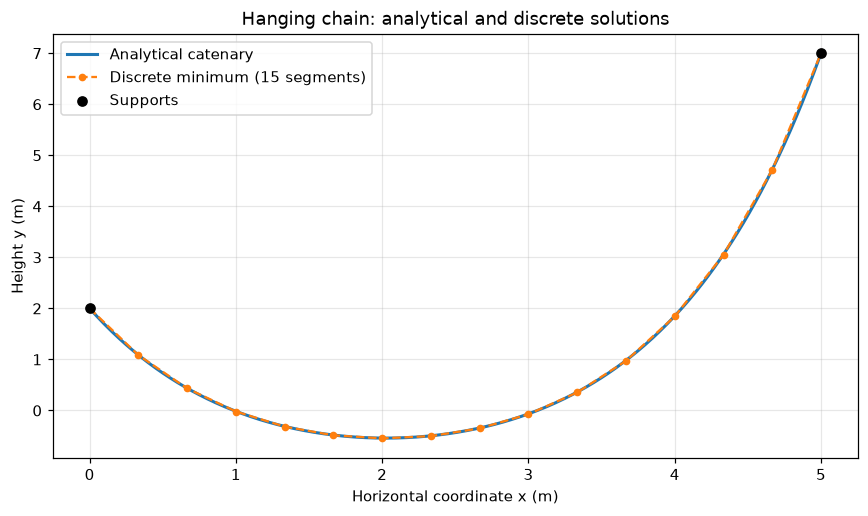

In [4]:
dense_x = np.linspace(0.0, horizontal_span, 500)
figure, axes = plt.subplots(figsize=(8, 4.8))
axes.plot(
    dense_x,
    analytic_chain_shape(dense_x),
    linewidth=2,
    label="Analytical catenary",
)
axes.plot(
    x_nodes,
    optimized_heights,
    "o--",
    markersize=4,
    label=f"Discrete minimum ({segment_count} segments)",
)
axes.scatter(
    [0.0, horizontal_span],
    [left_height, right_height],
    color="black",
    zorder=4,
    label="Supports",
)
axes.set(
    xlabel="Horizontal coordinate x (m)",
    ylabel="Height y (m)",
    title="Hanging chain: analytical and discrete solutions",
)
axes.grid(True, alpha=0.3)
axes.legend()
figure.tight_layout()
plt.show()


## Interpretation and limitations

The analytical solution is a catenary. The length multiplier adds a constant to the gravitational energy density per unit length, and its combination with the height gives the chain's tension magnitude; the invariant horizontal tension is $mg\alpha$. Changing the vertical datum shifts $C$ and $\Lambda$ together but does not change the chain shape or tension.

The numerical solution is a piecewise-linear discretization with fixed horizontal node locations. It satisfies the chosen polygonal length constraint; it is not an unconstrained two-dimensional discretization of every possible chain shape. Increasing the segment count provides a simple convergence check.